In [52]:
import numpy as np
import pandas as pd

from sklearn.metrics import root_mean_squared_error 


import matplotlib.pyplot as plt

import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')


In [41]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv" )
y = df['Milk']
print(y)
print("len : ",len(y))

0      589
1      561
2      640
3      656
4      727
      ... 
163    858
164    817
165    827
166    797
167    843
Name: Milk, Length: 168, dtype: int64
len :  168


We are trying different prediction methods one by one—starting from the simplest ones and moving to advanced ones.

We test them all on your milk production dataset to see which method gives us the most accurate results with the lowest amount of error.

# Centred Rolling Mean

rolling mean (also called a moving average) is a technique used to smooth out short-term fluctuations and highlight longer-term trends in time series data.

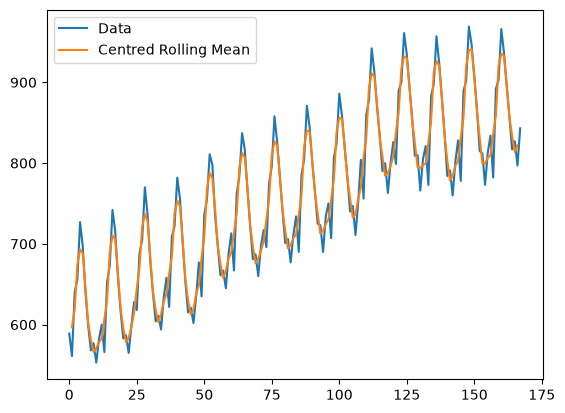

In [21]:
span = 3   # first n-1 will be nan values
fcast = y.rolling(window = span , center=True).mean()   # first and last would be missed as we rolling mean
plt.plot(y , label='Data')
plt.plot(fcast, label = 'Centred Rolling Mean')
plt.legend(loc= 'best')
plt.show()

# Trailing Moving Average / Trailing Rolling Mean
A smoothing technique that calculates the average using only past and current data points, commonly used to prevent looking into the future.

In [42]:
y_train , y_test = df['Milk'][:-12] , df['Milk'][-12:]
y_train.shape, y_test.shape

((156,), (12,))

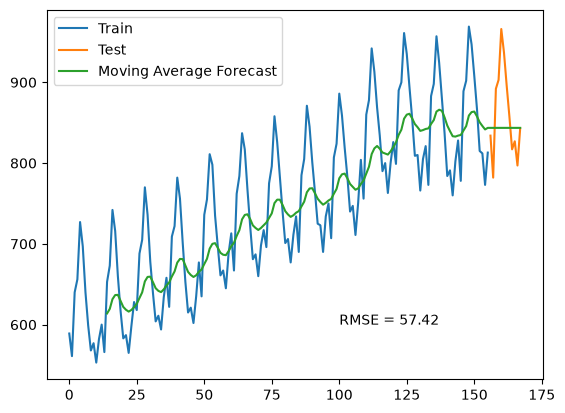

In [51]:
span = 15
fcast = y_train.rolling(window = span).mean()
MA = fcast.iloc[-1]
MA_Series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast , MA_Series] , ignore_index=True) # moving average forecast

plt.plot(y_train , label = 'Train')
plt.plot(y_test , label = 'Test')
plt.plot(MA_fcast , label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test , MA_Series) , 2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

# Simple Exponential smoothing
A forecasting method for data with no trend or seasonality that predicts future values using a weighted average where recent data gets more weight ($\alpha$) and older data fades exponentially.

In [53]:
from statsmodels.tsa.api import SimpleExpSmoothing

In [64]:
y_train

0      589
1      561
2      640
3      656
4      727
      ... 
151    867
152    815
153    812
154    773
155    813
Name: Milk, Length: 156, dtype: int64

E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


Text(100, 600, 'RMSE = 60.42')

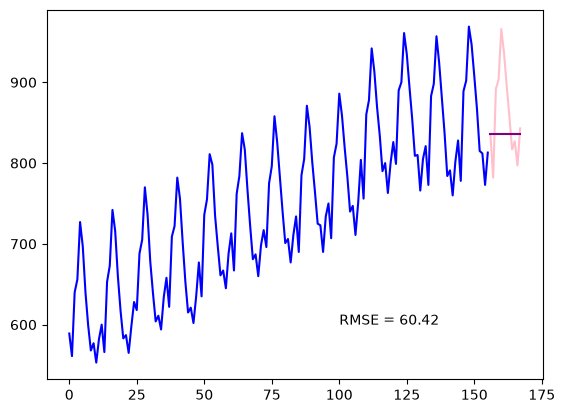

In [61]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train)

fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')


# Holt's Linear Trend Method
Holt's Linear Trend Method extends simple exponential smoothing by adding a trend component ($\beta$), allowing you to forecast time series data that has a clear upward or downward direction.

In [67]:
from statsmodels.tsa.api import Holt

E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


Text(100, 600, 'RMSE = 56.93')

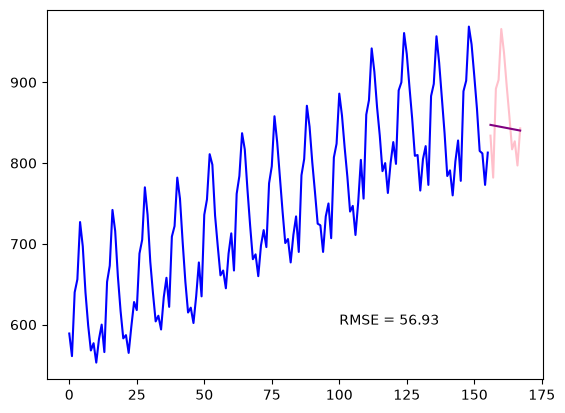

In [68]:
alpha ,beta = 0.1 , 0.2
holt = Holt(y_train)

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# Exponential Smoothing
Exponential Smoothing predicts future values by giving more weight to recent data and less weight to older data.

E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


Text(100, 600, 'RMSE = 56.62')

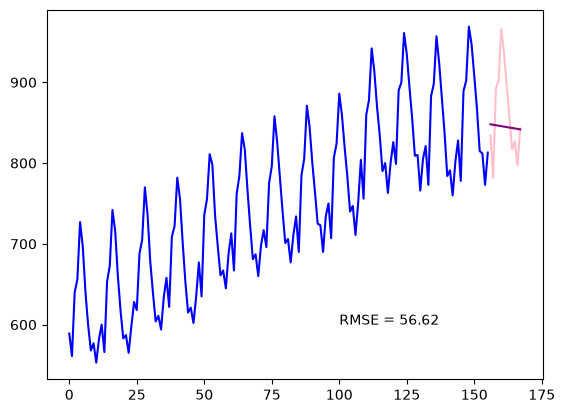

In [69]:
alpha ,beta = 0.1 , 0.2
holt = Holt(y_train , exponential=True)  # just changes equation but output looks same

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# Additive Damped Trend
A variation of Holt's linear trend that gradually flattens (damps) the trend line over time, preventing long-term forecasts from growing or declining unrealistically.

Text(100, 600, 'RMSE = 57.15')

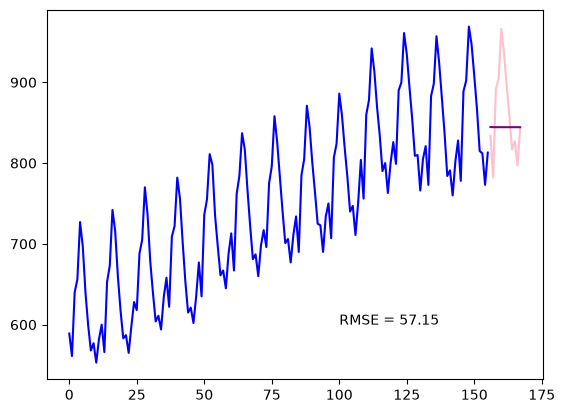

In [81]:
alpha ,beta, phi = 0.1 , 0.2, 0.3
holt = Holt(y_train , damped_trend=True)   

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta , damping_trend=phi , optimized=False)
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# Exponential Trend
A variation of Holt's linear method where the trend grows or declines multiplicatively (compounding) rather than linearly, allowing it to capture accelerating growth or decay patterns.

Text(100, 600, 'RMSE = 57.14')

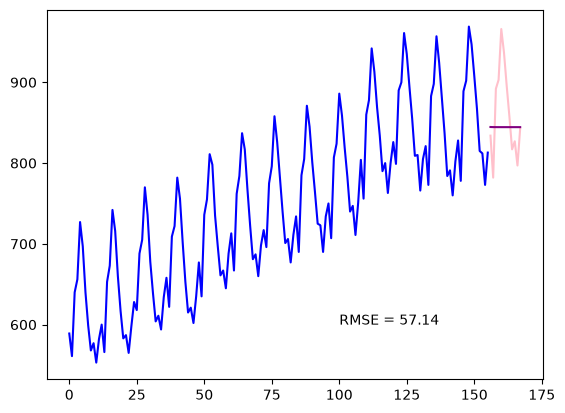

In [82]:
alpha ,beta, phi = 0.1 , 0.2, 0.3
holt = Holt(y_train , damped_trend=True , exponential=True)   

fit1 = holt.fit(smoothing_level= alpha , smoothing_trend = beta , damping_trend=phi , optimized=False)
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# Exponential Smoothing
A forecasting method that captures level, trend ($\beta$), and seasonality ($\gamma$) simultaneously by applying weighted averages where recent data gets more importance.

In [84]:
from statsmodels.tsa.api import ExponentialSmoothing

Text(100, 600, 'RMSE = 9.98')

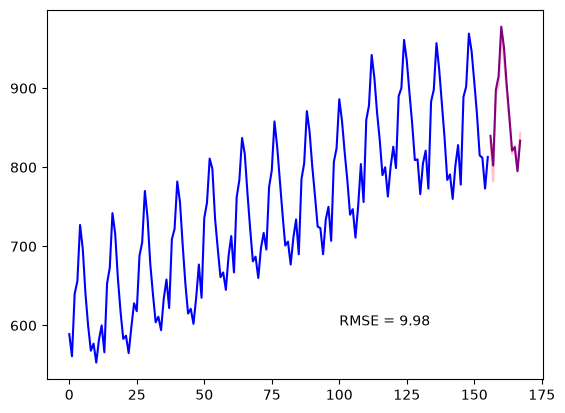

In [89]:
alpha ,beta, gamma = 0.1 , 0.2, 0.1
hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(smoothing_level= alpha , smoothing_trend = beta` , smoothing_seasonal=gamma )
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

Automatic Optimization

Text(100, 600, 'RMSE = 11.93')

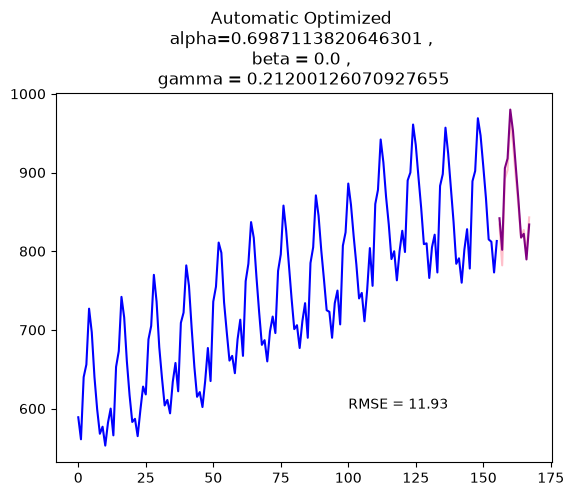

In [99]:
 
hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(optimized=True )  # calculated best garams does gridsearch of values
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

plt.title(f'Automatic Optimized \nalpha={alpha} , \nbeta = {beta} , \ngamma = {gamma}')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

In [94]:
# fit1.params

In [95]:
# optimized values
alpha = fit1.params['smoothing_level']
beta = fit1.params['smoothing_trend']
gamma = fit1.params['smoothing_seasonal']


# Exponential Smoothing

In [104]:
from tqdm import tqdm

In [105]:
alpha , beta , gamma = np.linspace(0.01,0.99,10) , np.linspace(0.01 , 0.99,10) , np.linspace(0.01 , 0.99,10)

scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
             
            hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   
            
            fit1 = hw_add.fit(smoothing_level=a , smoothing_trend=b, smoothing_seasonal=g)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b,g, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta', 'gamma','score'])
df_scores.sort_values('score')

 50%|█████     | 5/10 [00:37<00:41,  8.28s/it]E:\Installed_Applications\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
100%|██████████| 10/10 [01:47<00:00, 10.71s/it]


,alpha,beta,gamma,score
890,0.881111,0.990000,0.010000,8.115590
980,0.990000,0.881111,0.010000,8.617297
800,0.881111,0.010000,0.010000,8.886892
900,0.990000,0.010000,0.010000,8.915553
700,0.772222,0.010000,0.010000,8.997069
...,...,...,...,...
396,0.336667,0.990000,0.663333,87.049342
398,0.336667,0.990000,0.881111,88.947453
387,0.336667,0.881111,0.772222,90.501422
388,0.336667,0.881111,0.881111,93.589143
